In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression 
from sklearn.linear_model import Ridge,Lasso
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from scipy.special import expit,softmax
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [3]:
# 데이터 생성 
wine = pd.read_csv('data/wine.csv')
print(wine.head(2))

# 2. data, label분리
data = wine[['alcohol', 'sugar', 'pH']].values
label = wine['class'].values


   alcohol  sugar    pH  class
0      9.4    1.9  3.51    0.0
1      9.8    2.6  3.20    0.0


In [11]:
# 데이터 분리-train_data,test_data
train_data, test_data, train_label, test_label = train_test_split(
    data, label, test_size=0.2, random_state=42)

# 데이터분리 - sub_data,val_data
# 훈련데이터 : 훈련세트, 검증세트, 테스트세트 
sub_data, val_data, sub_label, val_label = train_test_split(
    train_data, train_label, test_size=0.2, random_state=42)


In [8]:
# 5. 트리알고니즘 적용
# max_depth=3, depth를 3까지만 가능
# dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt = DecisionTreeClassifier(random_state=42)
# 훈련
dt.fit(sub_data, sub_label)
#정확도
print(dt.score(sub_data, sub_label))
print(dt.score(val_data, val_label))



0.9971133028626413
0.864423076923077


In [12]:
# 특성 중요도 - 특성중에 어떤것이 가장 영향이 큰지를 알수 있음.
# alcohol  sugar    pH
print(dt.feature_importances_)

print(dt.score(sub_data, sub_label))
print(dt.score(test_data,test_label))

[0.23614177 0.50084785 0.26301038]
0.9971133028626413
0.8569230769230769


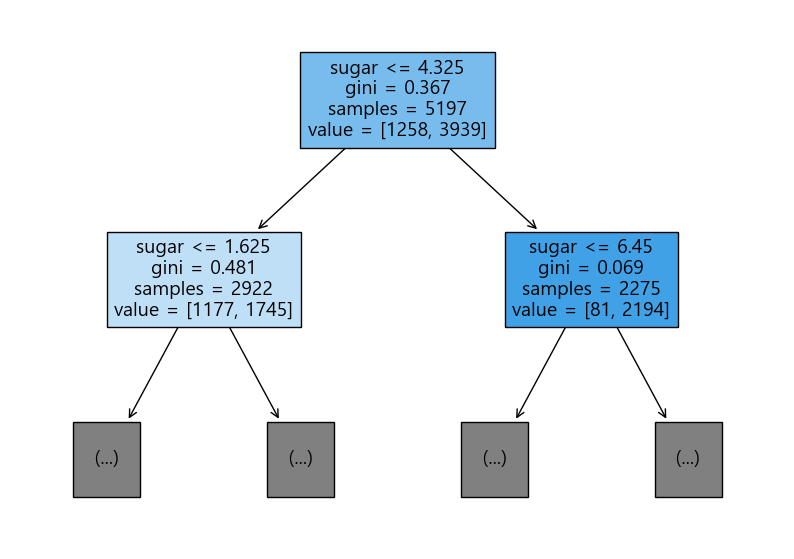

In [7]:
# 그래프 그리기
plt.figure(figsize=(10,7))
# plot_tree(dt)   #max_depth=1 : tree1까지만 보여줌, filled=True : 색상진하게
plot_tree(dt,max_depth=1, filled=True, feature_names=['alcohol','sugar','pH'])
plt.show()         # feature_names : 특성의 값이 표시됨.



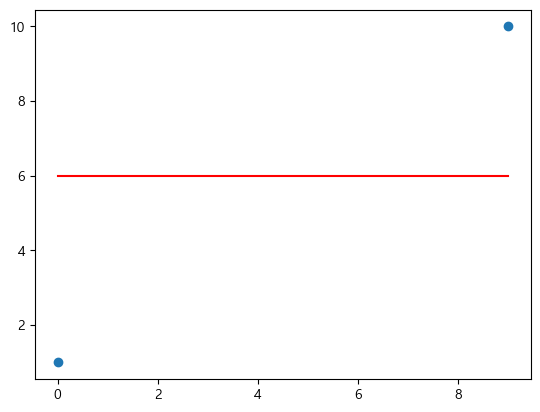

In [100]:
alist = list(range(10))
plt.scatter([0,9],[1,10])
plt.plot(alist,[6]*len(alist),color='r')
plt.show()